# Phase 4 — Deep Evaluation, Error Analysis, Grad-CAM & OOD Stress Test

Evaluasi mendalam seluruh 6 model terlatih (**Phase 2 Scratch Baseline** + **Phase 3 Transfer Learning Ablation**) di atas pipeline `tf.data` (`224 × 224`, `center_crop=True`, input mentah `[0..255]` RGB):

| Run ID | Model | Strategi | Preprocessing (In-Model) | Checkpoint |
| :--- | :--- | :--- | :--- | :--- |
| **Exp-1A** | Naive CNN (2 Conv + Flatten) | Scratch | `[0, 1]` | `exp1a_naive_cnn.keras` |
| **Exp-1B** | Proper CNN (4 Conv + BN + GAP) | Scratch | `[0, 1]` | `exp1b_proper_cnn.keras` |
| **Exp-2A** | MobileNetV2 | Frozen Feature Extractor | `[-1, 1]` | `exp2a_mobilenetv2_frozen.keras` |
| **Exp-2B** | MobileNetV2 | Selective FT (top 30%, BN frozen) | `[-1, 1]` | `exp2b_mobilenetv2_finetuned.keras` |
| **Exp-3A** | ResNet50 | Frozen Feature Extractor | BGR mean sub | `exp3a_resnet50_frozen.keras` |
| **Exp-3B** | ResNet50 | Selective FT (top 30%, BN frozen) | BGR mean sub | `exp3b_resnet50_finetuned.keras` |

**Protokol Ketat Phase 4:**
1. **Threshold Tuning (`Val Set` Saja):** Menentukan ambang batas optimal `t_opt` hanya pada Validation set (`282` citra) sebelum menyentuh Test set.
2. **One-Shot Test Evaluation (`Test Set = 282` citra):** Membuka Test set tepat satu kali untuk seluruh 6 model (Accuracy, Loss, Precision, Recall, F1, ROC-AUC, PR-AUC, Confusion Matrix, & McNemar test).
3. **Benchmark Efisiensi GPU T4:** Latensi inferensi single-image (`ms`), batch-32 throughput (`img/s`), parameter, dan ukuran model (`MB`).
4. **Error Analysis & Grad-CAM (`RQ3`):** Inspeksi visual FP/FN serta Grad-CAM *pre-sigmoid logit* untuk memverifikasi fokus model ke tekstur karya seni vs *shortcut*.
5. **OOD Stress Test (`RQ4`):** Uji ketahanan pada **30 citra eksternal** (`15` WikiArt museum + `5` Midjourney v6 + `5` FLUX.1-Dev + `5` DALL-E 3) dengan jarak pHash ≥ 14 dari dataset utama.


In [3]:
# Cell 1 — Colab Auto-Bootstrap (GitHub Repo + Fast Release Zip + 6 Models + 30 OOD Dataset)
import os
import shutil
import subprocess
import sys
import zipfile
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/Indraku19/real-art-vs-ai-generated-art.git'
RELEASE_ZIP_URL = (
    'https://github.com/Indraku19/real-art-vs-ai-generated-art/releases/'
    'download/v1.0-dataset/processed_images_224.zip'
)
COLAB_DIR = Path('/content/real-art-vs-ai-generated-art')

MODEL_FILES = [
    'exp1a_naive_cnn.keras',
    'exp1b_proper_cnn.keras',
    'exp2a_mobilenetv2_frozen.keras',
    'exp2b_mobilenetv2_finetuned.keras',
    'exp3a_resnet50_frozen.keras',
    'exp3b_resnet50_finetuned.keras',
]

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')

    if not COLAB_DIR.exists():
        subprocess.check_call(['git', 'clone', REPO_URL, str(COLAB_DIR)])
    else:
        subprocess.check_call(['git', '-C', str(COLAB_DIR), 'pull', '--ff-only'])
    os.chdir(COLAB_DIR)

    # 1. Main processed 224x224 dataset (2,820 images)
    img_dir = Path('data/processed/images')
    img_dir.mkdir(parents=True, exist_ok=True)
    if len(list(img_dir.glob('*.png'))) < 2820:
        zip_tmp = Path('/tmp/processed_images_224.zip')
        print('Downloading pre-cleaned 224x224 dataset cache from GitHub Release...')
        subprocess.check_call(['curl', '-fSL', RELEASE_ZIP_URL, '-o', str(zip_tmp)])
        with zipfile.ZipFile(zip_tmp, 'r') as zf:
            zf.extractall(img_dir)
        zip_tmp.unlink(missing_ok=True)
        print('Extracted main dataset PNGs:', len(list(img_dir.glob('*.png'))))

    drive_root = Path('/content/drive/MyDrive/Real-vs-AI-Art-Classification')

    # 2. Copy all 6 trained .keras checkpoints from Drive 04_Models/
    drive_models_dir = drive_root / '04_Models'
    local_models_dir = Path('models')
    local_models_dir.mkdir(parents=True, exist_ok=True)
    for fname in MODEL_FILES:
        dst = local_models_dir / fname
        if not dst.exists():
            src = drive_models_dir / fname
            if not src.exists():
                raise FileNotFoundError(f'Model checkpoint missing in Drive: {src}')
            print(f'Copying {fname} from Google Drive...')
            shutil.copy2(src, dst)

    # 3. Extract 30 curated OOD stress test images from Drive 05_OOD_Dataset/
    ood_img_dir = Path('data/ood/images')
    ood_meta_path = Path('data/ood/ood_metadata.csv')
    if len(list(ood_img_dir.glob('*.png'))) < 30 or not ood_meta_path.exists():
        ood_zip = drive_root / '05_OOD_Dataset' / 'ood_stress_test_30.zip'
        if not ood_zip.exists():
            raise FileNotFoundError(f'OOD zip bundle missing in Drive: {ood_zip}')
        Path('data/ood').mkdir(parents=True, exist_ok=True)
        print('Extracting 30-image OOD Stress Test dataset from Drive...')
        with zipfile.ZipFile(ood_zip, 'r') as zf:
            zf.extractall('data/ood')

    assert len(list(img_dir.glob('*.png'))) == 2820, 'Main dataset incomplete!'
    assert all((local_models_dir / f).exists() for f in MODEL_FILES), 'Missing .keras checkpoints!'
    assert len(list(ood_img_dir.glob('*.png'))) == 30 and ood_meta_path.exists(), 'OOD dataset incomplete!'

    if str(COLAB_DIR) not in sys.path:
        sys.path.insert(0, str(COLAB_DIR))
    print('Environment: Google Colab | Project Root:', Path.cwd())
    print('Verified: 2,820 main PNGs | 6 .keras models | 30 OOD PNGs')
else:
    if Path.cwd().name == 'notebooks':
        os.chdir(Path.cwd().parent)
    if str(Path.cwd()) not in sys.path:
        sys.path.insert(0, str(Path.cwd()))
    print('Environment: Local | Project Root:', Path.cwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Environment: Google Colab | Project Root: /content/real-art-vs-ai-generated-art
Verified: 2,820 main PNGs | 6 .keras models | 30 OOD PNGs


In [4]:
# Cell 2 — Imports, Reproducibility Seed, Datasets & Load All 6 Models
import json
import math
import shutil
import time
from datetime import datetime
from pathlib import Path

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

import importlib
import src.data_pipeline  # registers custom ResNet50PreprocessLayer
importlib.reload(src.data_pipeline)
from src.config import (
    EXPERIMENT_LOG_PATH,
    EXPERIMENTS_DIR,
    FIGURES_DIR,
    IMG_SIZE,
    LABEL_MAP,
    MODELS_DIR,
    OOD_DIR,
    PROCESSED_DIR,
    SEED,
    set_global_seed,
)
from src.data_pipeline import (
    _decode_and_resize,
    build_tf_dataset,
    load_keras_model_compat,
    load_splits,
)

set_global_seed(SEED)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'axes.edgecolor': '#cbd5e1',
    'axes.linewidth': 0.9,
})

print('TensorFlow:', tf.__version__, '| Keras:', keras.__version__)
gpus = tf.config.list_physical_devices('GPU')
print('GPUs detected:', gpus if gpus else 'None (CPU mode)')

splits_df = load_splits()
val_df = splits_df[splits_df['split'] == 'val'].reset_index(drop=True)
test_df = splits_df[splits_df['split'] == 'test'].reset_index(drop=True)

val_ds = build_tf_dataset(splits_df, 'val', augment=False, center_crop=True, cache=True, shuffle=False)
test_ds = build_tf_dataset(splits_df, 'test', augment=False, center_crop=True, cache=True, shuffle=False)

y_val = val_df['label'].to_numpy(dtype=int)
y_test = test_df['label'].to_numpy(dtype=int)

print(f'Val samples: {len(y_val)} (Real={int((y_val==0).sum())}, AI={int((y_val==1).sum())})')
print(f'Test samples: {len(y_test)} (Real={int((y_test==0).sum())}, AI={int((y_test==1).sum())})')

MODEL_SPECS = [
    {
        'run_id': 'Exp-1A',
        'filename': 'exp1a_naive_cnn.keras',
        'short_name': 'Naive CNN',
        'family': 'Scratch CNN',
        'strategy': 'Scratch (2 Conv + Flatten)',
        'color': '#dc2626',
        'spatial_layer': 'conv2',
    },
    {
        'run_id': 'Exp-1B',
        'filename': 'exp1b_proper_cnn.keras',
        'short_name': 'Proper CNN',
        'family': 'Scratch CNN',
        'strategy': 'Scratch (4 Conv + BN + GAP)',
        'color': '#ea580c',
        'spatial_layer': 'relu_b4',
    },
    {
        'run_id': 'Exp-2A',
        'filename': 'exp2a_mobilenetv2_frozen.keras',
        'short_name': 'MNv2 Frozen',
        'family': 'MobileNetV2',
        'strategy': 'Frozen Feature Extractor',
        'color': '#3b82f6',
        'spatial_layer': 'mobilenetv2_1.00_224',
    },
    {
        'run_id': 'Exp-2B',
        'filename': 'exp2b_mobilenetv2_finetuned.keras',
        'short_name': 'MNv2 Fine-Tuned',
        'family': 'MobileNetV2',
        'strategy': 'Selective FT (top 30%, BN frozen)',
        'color': '#1d4ed8',
        'spatial_layer': 'mobilenetv2_1.00_224',
    },
    {
        'run_id': 'Exp-3A',
        'filename': 'exp3a_resnet50_frozen.keras',
        'short_name': 'RN50 Frozen',
        'family': 'ResNet50',
        'strategy': 'Frozen Feature Extractor',
        'color': '#10b981',
        'spatial_layer': 'resnet50',
    },
    {
        'run_id': 'Exp-3B',
        'filename': 'exp3b_resnet50_finetuned.keras',
        'short_name': 'RN50 Fine-Tuned',
        'family': 'ResNet50',
        'strategy': 'Selective FT (top 30%, BN frozen)',
        'color': '#047857',
        'spatial_layer': 'resnet50',
    },
]

def count_params_keras3(model: keras.Model) -> tuple[int, int]:
    total = sum(int(np.prod(w.shape)) for w in model.weights)
    trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
    return total, trainable

MODELS = {}
MODEL_META = {}
for spec in MODEL_SPECS:
    rid = spec['run_id']
    mpath = MODELS_DIR / spec['filename']
    model = load_keras_model_compat(mpath, compile=False)
    total_p, train_p = count_params_keras3(model)
    size_mb = round(mpath.stat().st_size / (1024 * 1024), 2)
    MODELS[rid] = model
    MODEL_META[rid] = {
        **spec,
        'model_size_mb': size_mb,
        'params_total': total_p,
        'params_trainable': train_p,
    }
    print(f'Loaded {rid:6s} | {mpath.name:34s} | {size_mb:6.2f} MB | params={total_p:>10,d}')

TensorFlow: 2.21.0 | Keras: 3.13.2
GPUs detected: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Val samples: 282 (Real=140, AI=142)
Test samples: 282 (Real=141, AI=141)
Loaded Exp-1A | exp1a_naive_cnn.keras              | 273.64 MB | params=23,907,521
Loaded Exp-1B | exp1b_proper_cnn.keras             |   4.92 MB | params=   422,881
Loaded Exp-2A | exp2a_mobilenetv2_frozen.keras     |  11.06 MB | params= 2,422,081
Loaded Exp-2B | exp2b_mobilenetv2_finetuned.keras  |  24.65 MB | params= 2,422,081
Loaded Exp-3A | exp3a_resnet50_frozen.keras        |  93.62 MB | params=23,850,113
Loaded Exp-3B | exp3b_resnet50_finetuned.keras     | 224.75 MB | params=23,850,113


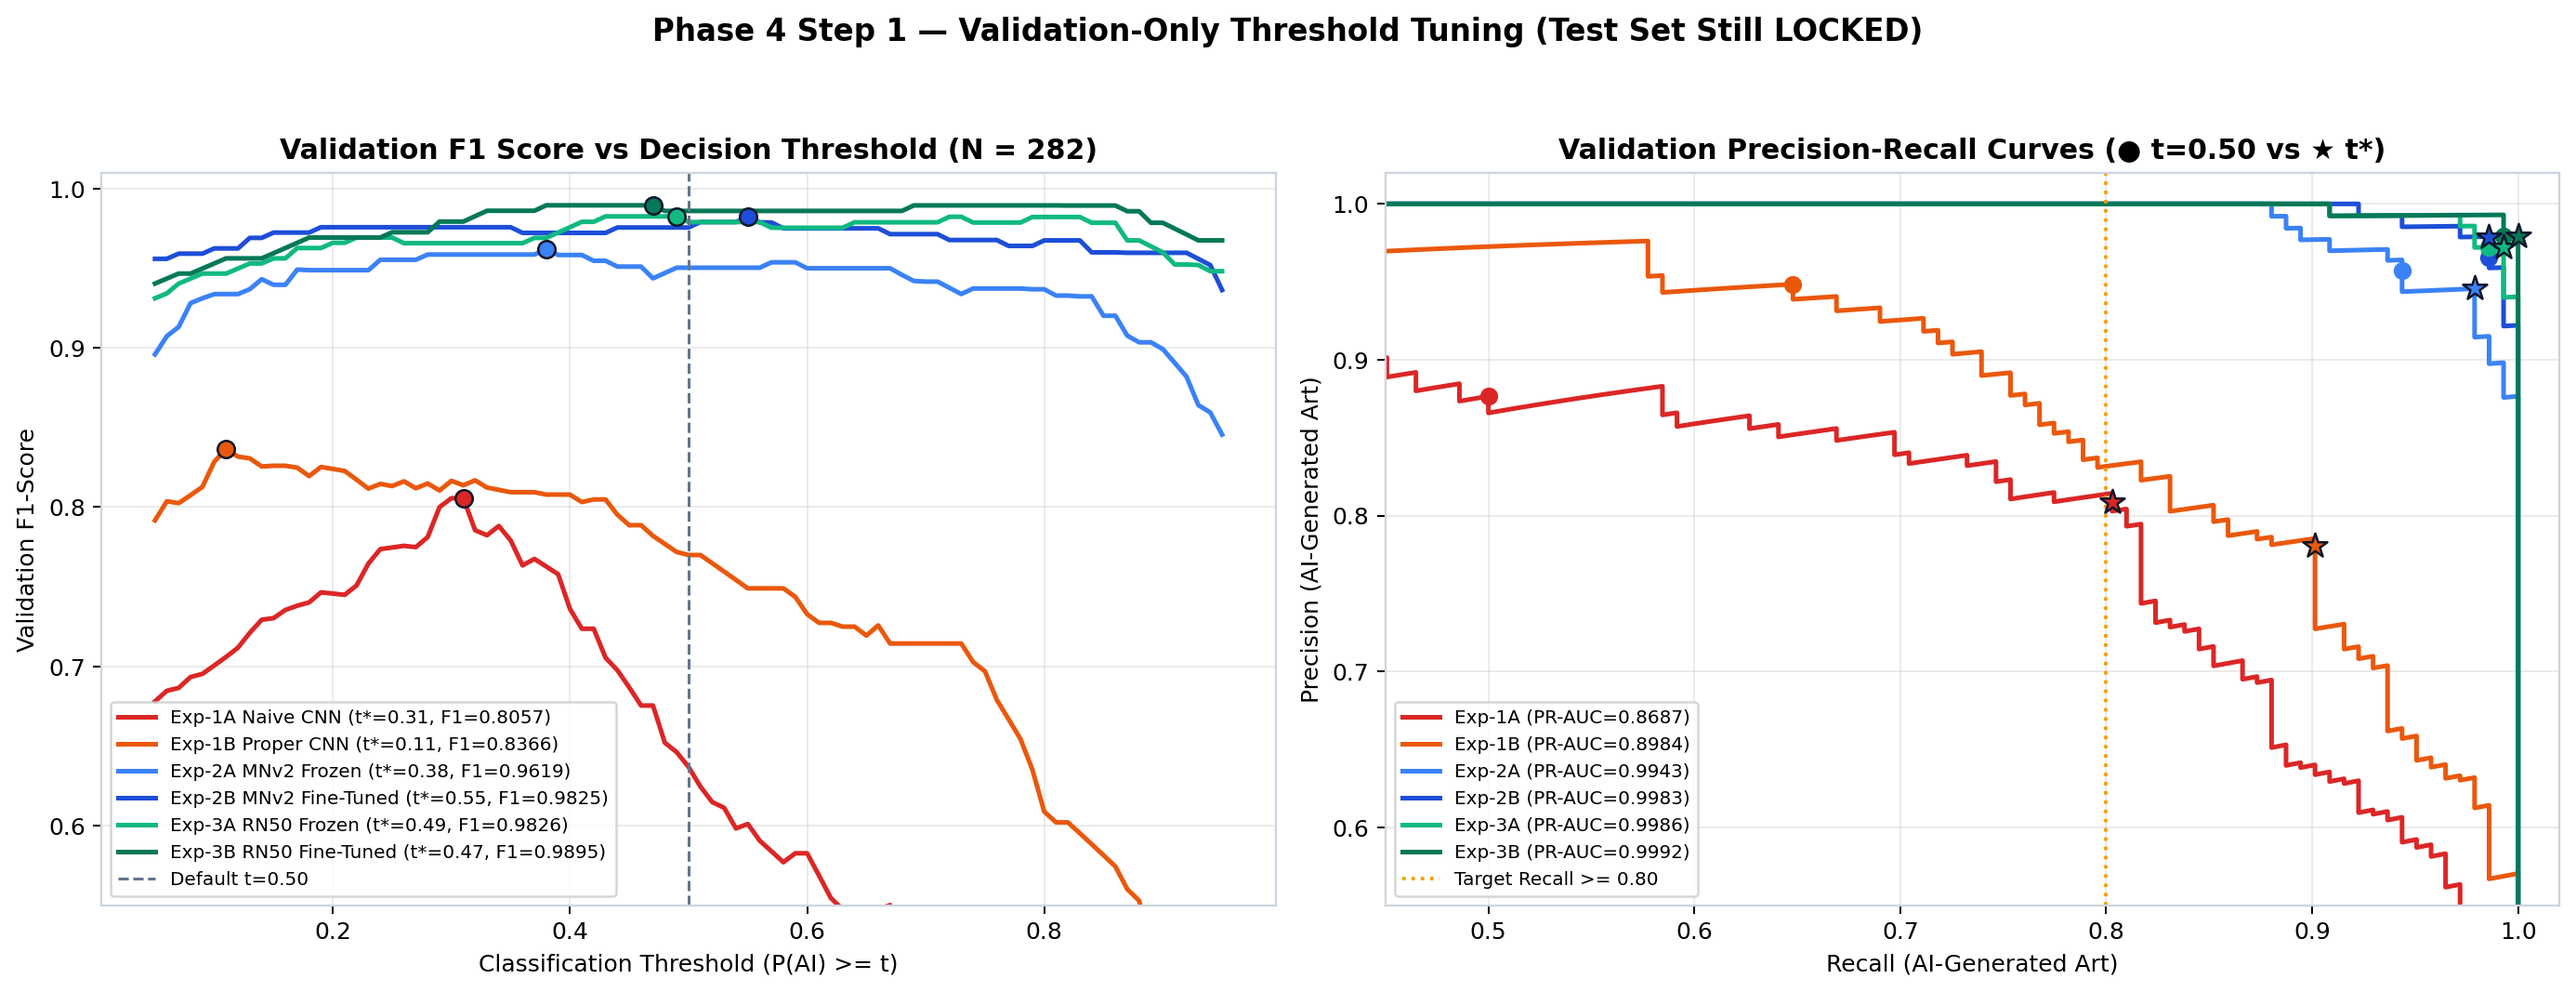

,Run ID,Model,Val Acc @0.50,Val F1 @0.50,Val Rec @0.50,Optimal t*,Val Acc @t*,Val F1 @t*,Val Rec @t*,Val PR-AUC
0,Exp-1A,Naive CNN,71.28%,0.6368,0.5000,0.31,80.50%,0.8057,0.8028,0.8687
1,Exp-1B,Proper CNN,80.50%,0.7699,0.6479,0.11,82.27%,0.8366,0.9014,0.8984
2,Exp-2A,MNv2 Frozen,95.04%,0.9504,0.9437,0.38,96.10%,0.9619,0.9789,0.9943
3,Exp-2B,MNv2 Fine-Tuned,97.52%,0.9756,0.9859,0.55,98.23%,0.9825,0.9859,0.9983
4,Exp-3A,RN50 Frozen,97.87%,0.9790,0.9859,0.49,98.23%,0.9826,0.9930,0.9986
5,Exp-3B,RN50 Fine-Tuned,98.58%,0.9860,0.9930,0.47,98.94%,0.9895,1.0000,0.9992


Saved: /content/real-art-vs-ai-generated-art/reports/figures/phase4_threshold_tuning.png


In [5]:
# Cell 3 — Threshold Tuning on Validation Set ONLY (p4_thresh)
def compute_binary_metrics(y_true: np.ndarray, probs: np.ndarray, threshold: float = 0.5) -> dict:
    probs_clip = np.clip(probs, 1e-7, 1.0 - 1e-7)
    preds = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, preds, labels=[0, 1]).ravel()
    return {
        'threshold': round(float(threshold), 4),
        'loss': round(float(log_loss(y_true, probs_clip, labels=[0, 1])), 4),
        'accuracy': round(float(accuracy_score(y_true, preds)), 4),
        'errors': int(fp + fn),
        'precision': round(float(precision_score(y_true, preds, zero_division=0)), 4),
        'recall': round(float(recall_score(y_true, preds, zero_division=0)), 4),
        'f1': round(float(f1_score(y_true, preds, zero_division=0)), 4),
        'roc_auc': round(float(roc_auc_score(y_true, probs)), 4),
        'pr_auc': round(float(average_precision_score(y_true, probs)), 4),
        'tn': int(tn),
        'fp': int(fp),
        'fn': int(fn),
        'tp': int(tp),
    }

val_probs = {}
val_default_metrics = {}
val_tuned_metrics = {}
optimal_thresholds = {}
thresh_grid = np.linspace(0.05, 0.95, 91)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 6.0), dpi=180)
fig.patch.set_facecolor('white')

thresh_rows = []
for spec in MODEL_SPECS:
    rid = spec['run_id']
    probs = MODELS[rid].predict(val_ds, verbose=0).ravel()
    val_probs[rid] = probs
    val_default_metrics[rid] = compute_binary_metrics(y_val, probs, threshold=0.50)

    sweep = []
    for t in thresh_grid:
        preds = (probs >= t).astype(int)
        rec = float(recall_score(y_val, preds, zero_division=0))
        f1 = float(f1_score(y_val, preds, zero_division=0))
        acc = float(accuracy_score(y_val, preds))
        sweep.append((round(float(t), 4), f1, rec, acc))

    feasible = [item for item in sweep if item[2] >= 0.80]
    pool = feasible if feasible else sweep
    # Maximize F1; tie-break closest to 0.50
    best_t, _, _, _ = max(pool, key=lambda item: (round(item[1], 6), -abs(item[0] - 0.50)))
    optimal_thresholds[rid] = float(best_t)
    val_tuned_metrics[rid] = compute_binary_metrics(y_val, probs, threshold=best_t)

    # Plot F1 vs threshold
    ax1.plot(
        [s[0] for s in sweep],
        [s[1] for s in sweep],
        color=spec['color'],
        linewidth=2.0,
        label=f"{rid} {spec['short_name']} (t*={best_t:.2f}, F1={val_tuned_metrics[rid]['f1']:.4f})",
    )
    ax1.scatter([best_t], [val_tuned_metrics[rid]['f1']], color=spec['color'], s=55, zorder=5, edgecolors='#0f172a')

    # Plot PR curve on Val set
    prec_curve, rec_curve, _ = precision_recall_curve(y_val, probs)
    ax2.plot(
        rec_curve,
        prec_curve,
        color=spec['color'],
        linewidth=2.0,
        label=f"{rid} (PR-AUC={val_default_metrics[rid]['pr_auc']:.4f})",
    )
    ax2.scatter(
        [val_default_metrics[rid]['recall']],
        [val_default_metrics[rid]['precision']],
        color=spec['color'],
        marker='o',
        s=45,
        zorder=5,
    )
    ax2.scatter(
        [val_tuned_metrics[rid]['recall']],
        [val_tuned_metrics[rid]['precision']],
        color=spec['color'],
        marker='*',
        s=120,
        edgecolors='#0f172a',
        zorder=6,
    )

    thresh_rows.append({
        'Run ID': rid,
        'Model': spec['short_name'],
        'Val Acc @0.50': f"{val_default_metrics[rid]['accuracy']*100:.2f}%",
        'Val F1 @0.50': val_default_metrics[rid]['f1'],
        'Val Rec @0.50': val_default_metrics[rid]['recall'],
        'Optimal t*': best_t,
        'Val Acc @t*': f"{val_tuned_metrics[rid]['accuracy']*100:.2f}%",
        'Val F1 @t*': val_tuned_metrics[rid]['f1'],
        'Val Rec @t*': val_tuned_metrics[rid]['recall'],
        'Val PR-AUC': val_default_metrics[rid]['pr_auc'],
    })

ax1.axvline(0.50, color='#64748b', linestyle='--', linewidth=1.2, label='Default t=0.50')
ax1.set_title('Validation F1 Score vs Decision Threshold (N = 282)', fontweight='bold')
ax1.set_xlabel('Classification Threshold (P(AI) >= t)')
ax1.set_ylabel('Validation F1-Score')
ax1.set_ylim(0.55, 1.01)
ax1.grid(alpha=0.25)
ax1.legend(fontsize=8.0, loc='lower left')

ax2.axvline(0.80, color='#f59e0b', linestyle=':', linewidth=1.5, label='Target Recall >= 0.80')
ax2.set_title('Validation Precision-Recall Curves (● t=0.50 vs ★ t*)', fontweight='bold')
ax2.set_xlabel('Recall (AI-Generated Art)')
ax2.set_ylabel('Precision (AI-Generated Art)')
ax2.set_xlim(0.45, 1.02)
ax2.set_ylim(0.55, 1.02)
ax2.grid(alpha=0.25)
ax2.legend(fontsize=8.0, loc='lower left')

fig.suptitle('Phase 4 Step 1 — Validation-Only Threshold Tuning (Test Set Still LOCKED)', fontsize=13, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.94])
thresh_fig_path = FIGURES_DIR / 'phase4_threshold_tuning.png'
fig.savefig(thresh_fig_path, dpi=180, bbox_inches='tight')
plt.show()

display(pd.DataFrame(thresh_rows))
print('Saved:', thresh_fig_path)

McNemar Exact Test (Exp-2B vs Exp-3B on Test Set): {"both_correct": 275, "both_wrong": 3, "exp2b_only_correct": 1, "exp3b_only_correct": 3, "discordant_pairs": 4, "exact_two_sided_p_value": 0.625}


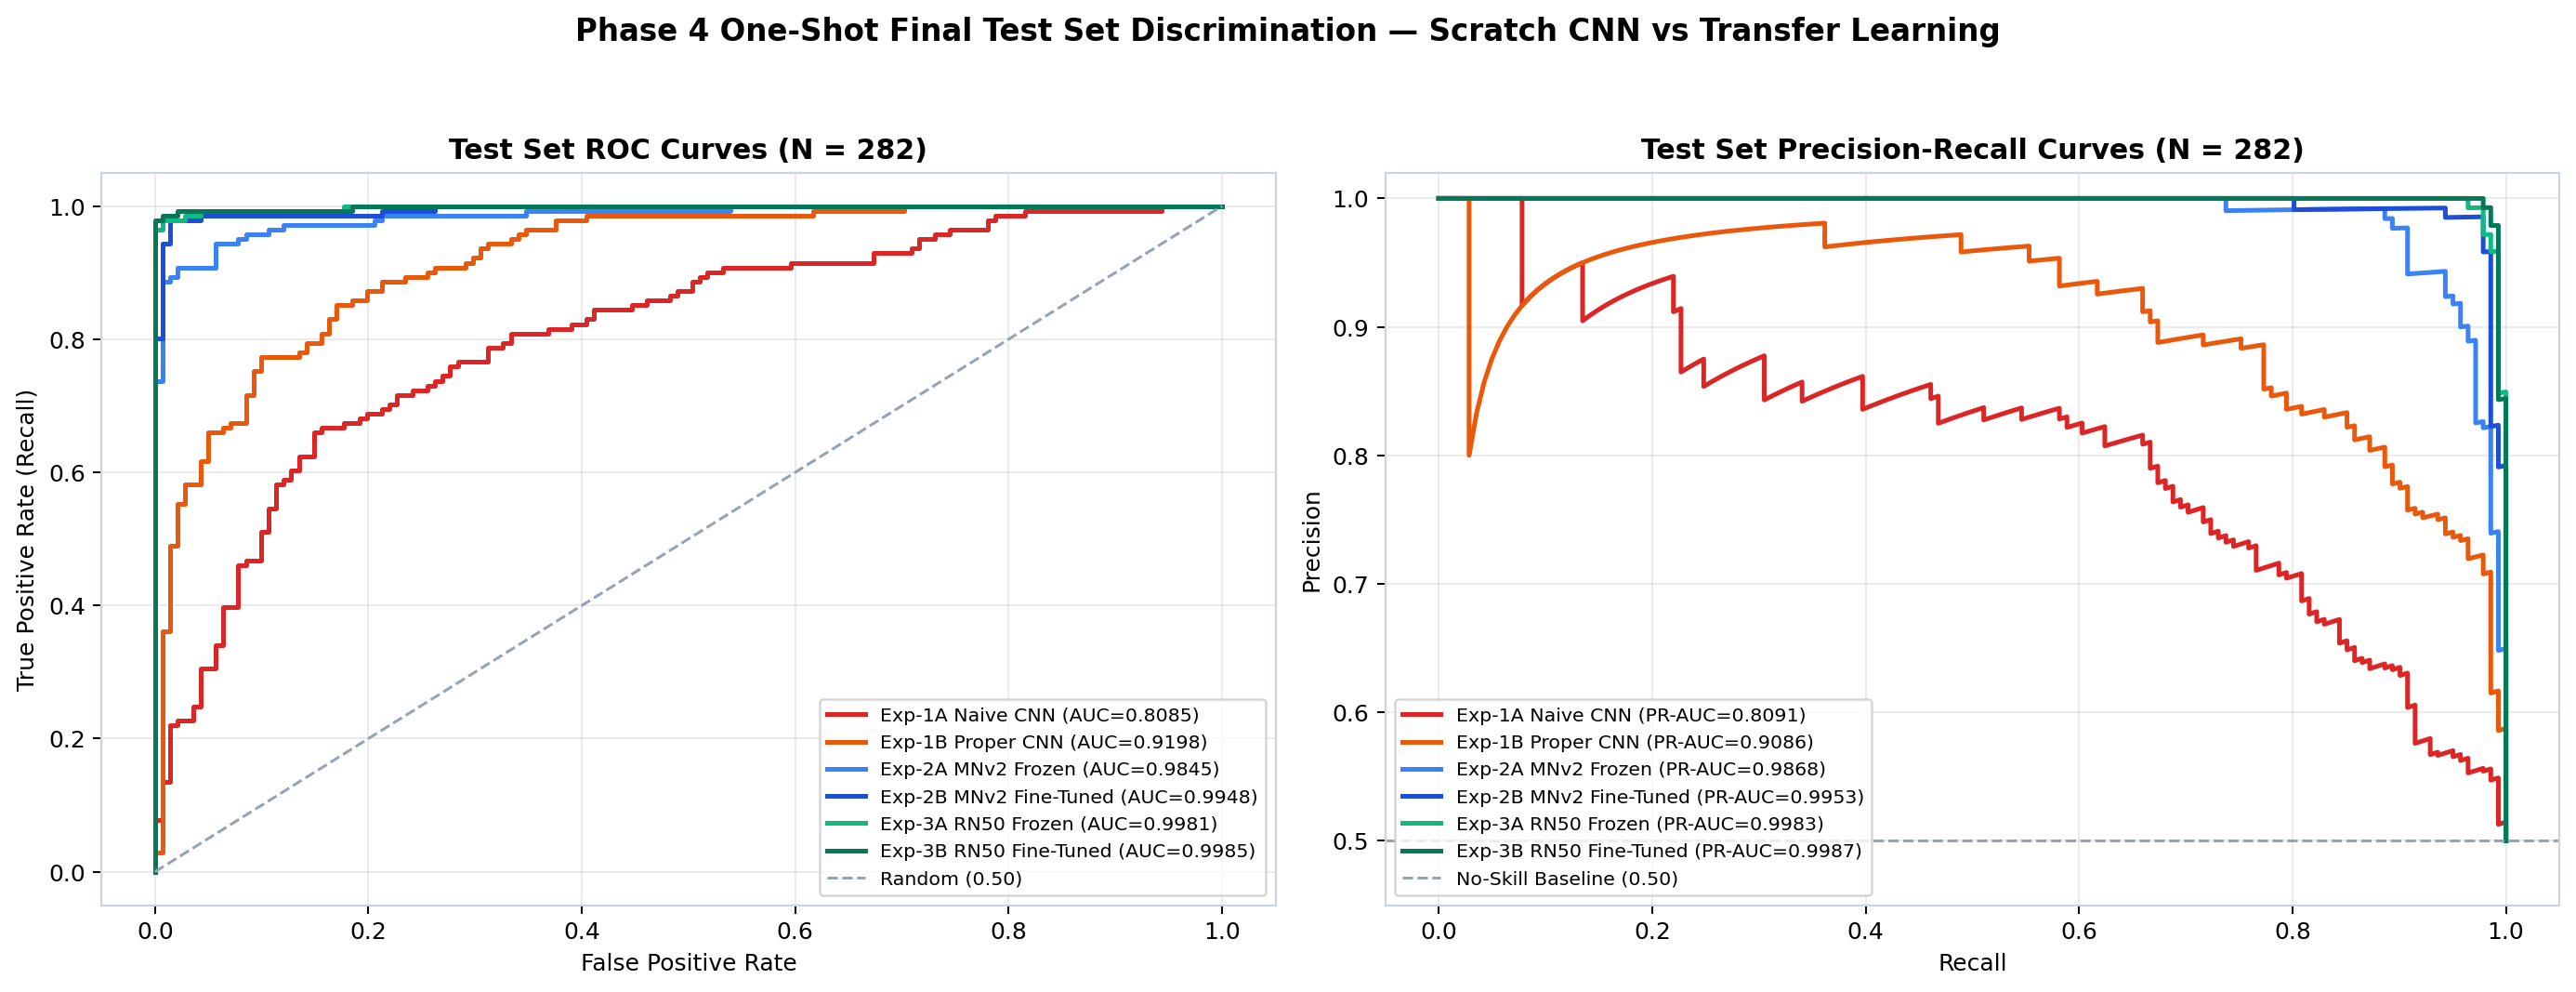

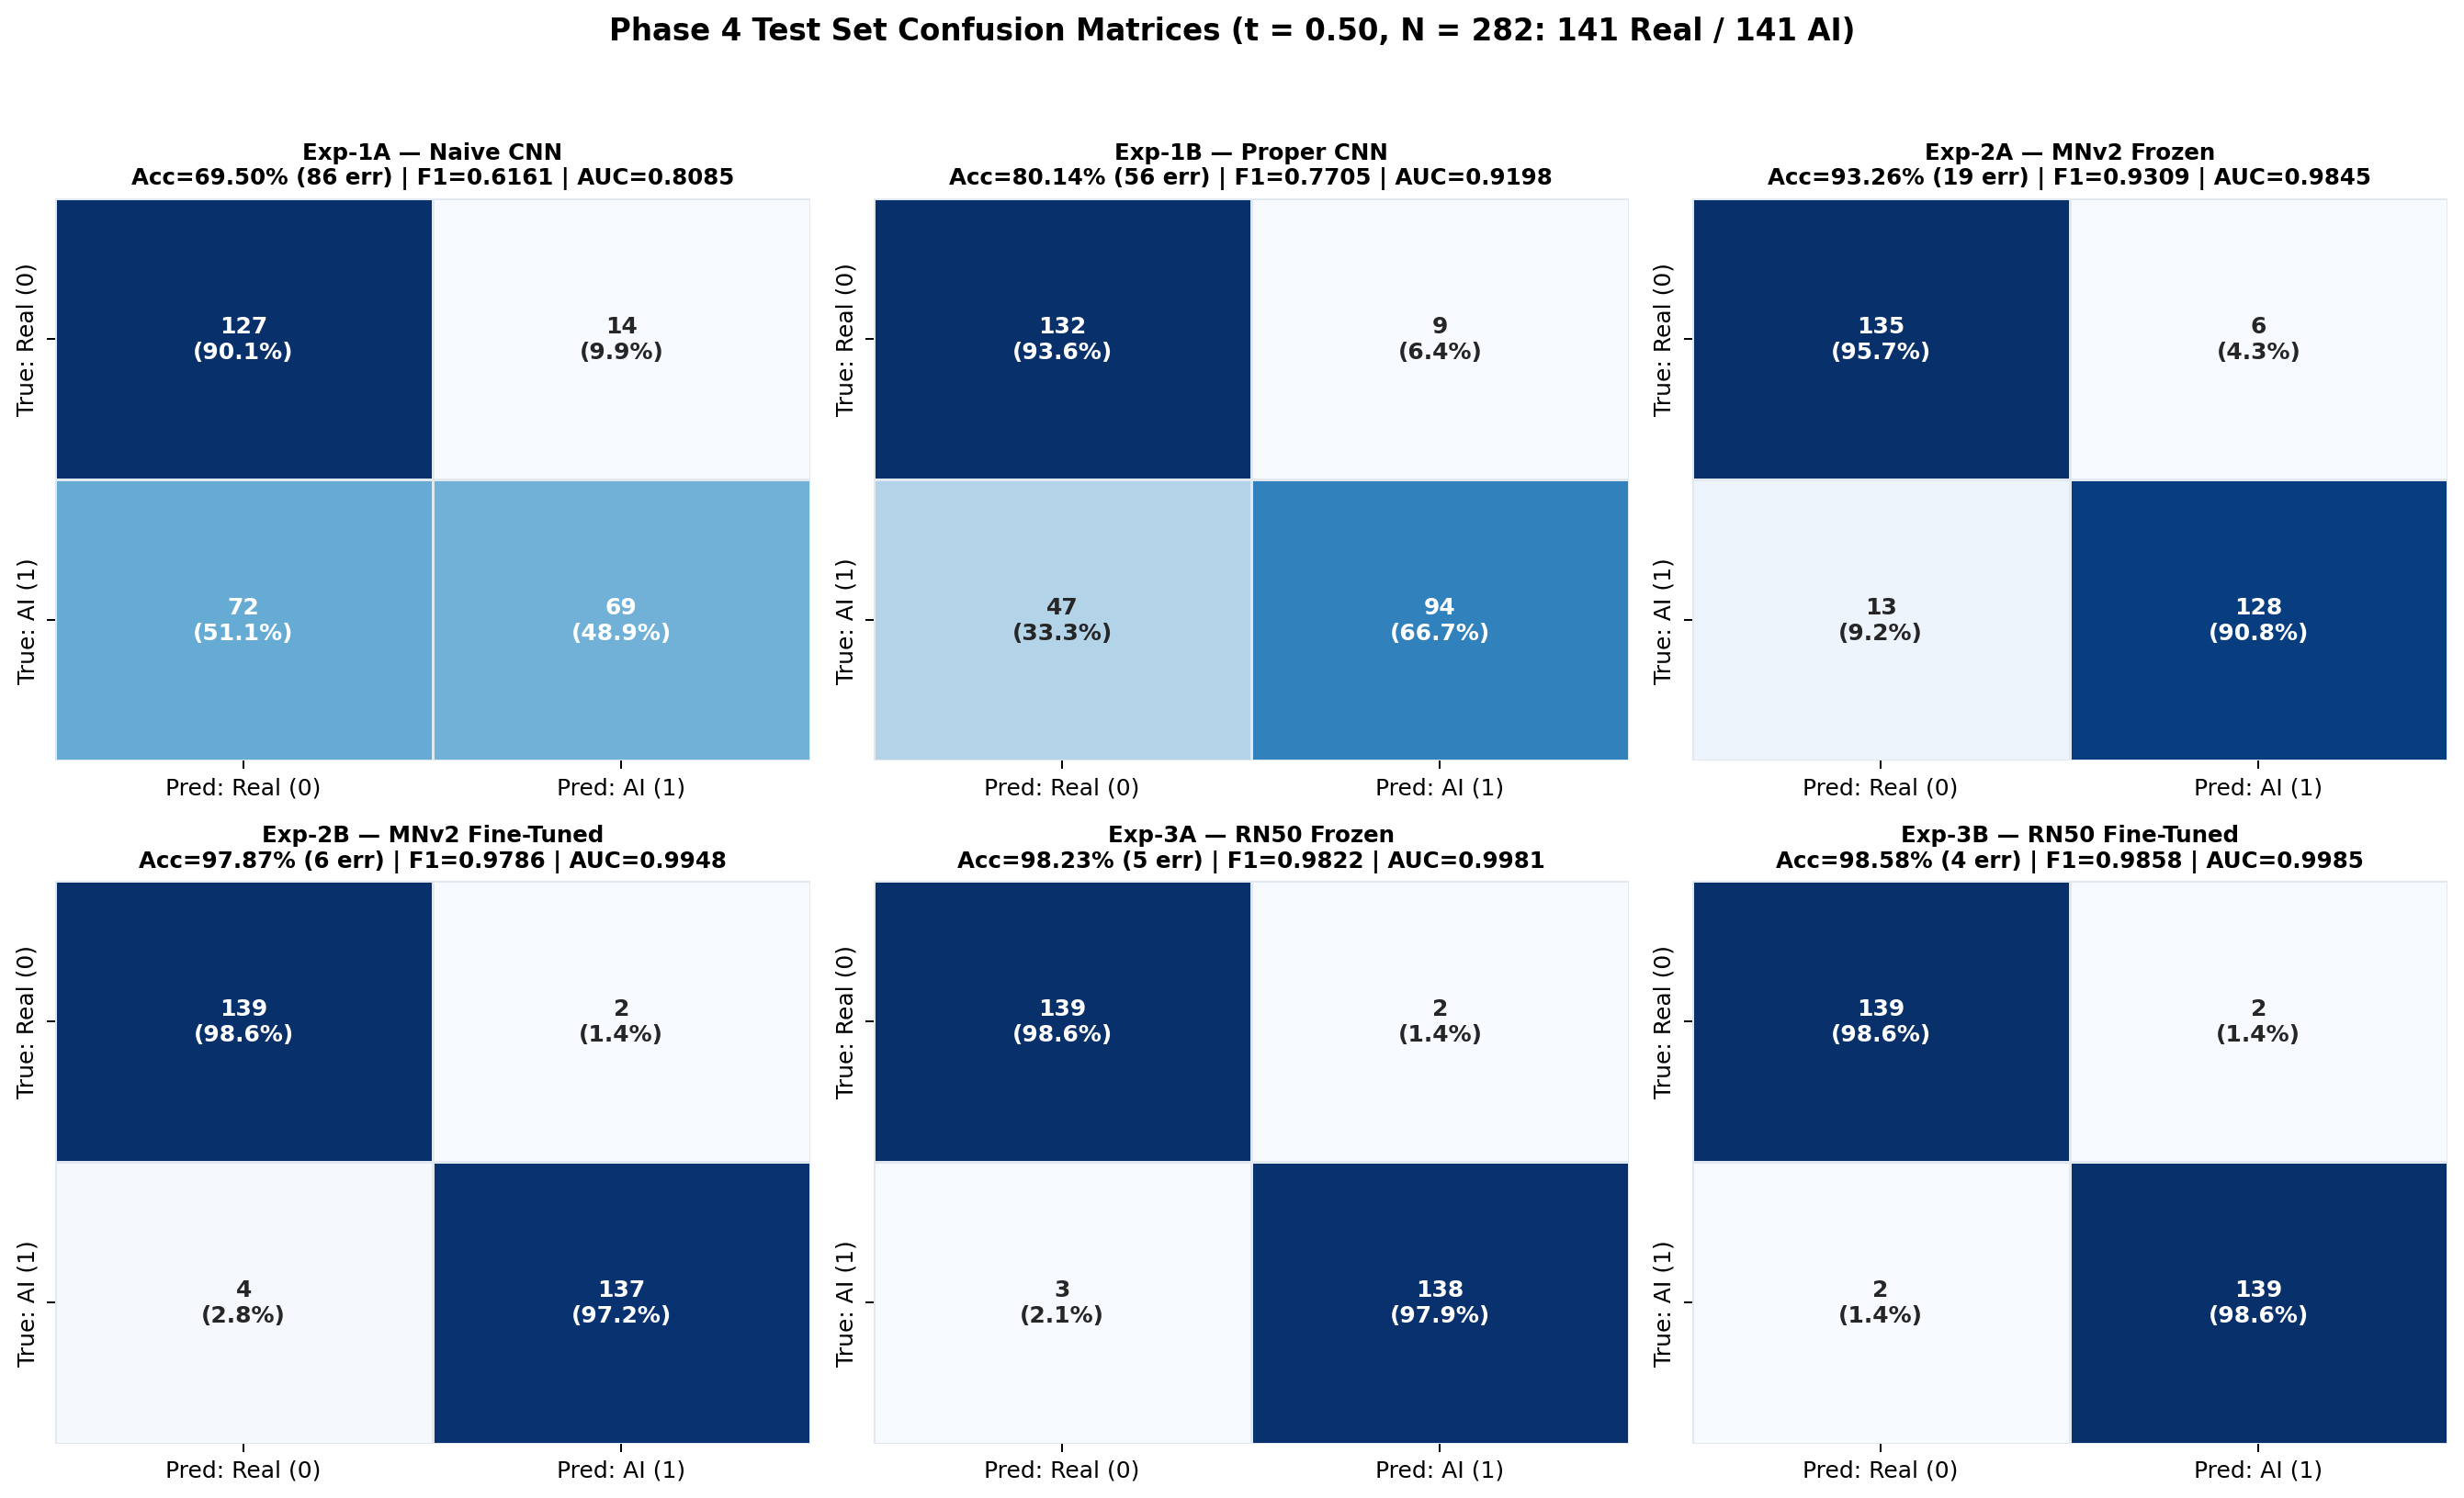

,Run ID,Model,Val Acc,Test Acc,Val->Test Δ (pp),Test Err (/282),Test Loss,Precision,Recall,F1,ROC-AUC,PR-AUC,Tuned t*,Test Acc @t*,Test F1 @t*
0,Exp-1A,Naive CNN,0.7128,0.6950,-1.78,86,0.5893,0.8313,0.4894,0.6161,0.8085,0.8091,0.31,0.7376,0.7338
1,Exp-1B,Proper CNN,0.8050,0.8014,-0.36,56,0.4658,0.9126,0.6667,0.7705,0.9198,0.9086,0.11,0.8227,0.8344
2,Exp-2A,MNv2 Frozen,0.9504,0.9326,-1.78,19,0.1607,0.9552,0.9078,0.9309,0.9845,0.9868,0.38,0.9362,0.9357
3,Exp-2B,MNv2 Fine-Tuned,0.9752,0.9787,0.35,6,0.0855,0.9856,0.9716,0.9786,0.9948,0.9953,0.55,0.9716,0.9712
4,Exp-3A,RN50 Frozen,0.9787,0.9823,0.36,5,0.0588,0.9857,0.9787,0.9822,0.9981,0.9983,0.49,0.9787,0.9787
5,Exp-3B,RN50 Fine-Tuned,0.9858,0.9858,0.00,4,0.0414,0.9858,0.9858,0.9858,0.9985,0.9987,0.47,0.9858,0.9859


Updated /content/real-art-vs-ai-generated-art/experiments/experiment_log.csv and saved /content/real-art-vs-ai-generated-art/experiments/phase4_test_predictions.csv


In [6]:
# Cell 4 — One-Shot Final Test Set Evaluation (N = 282) & McNemar Test (p4_test)
test_probs = {}
test_default_metrics = {}
test_tuned_metrics = {}

for spec in MODEL_SPECS:
    rid = spec['run_id']
    probs = MODELS[rid].predict(test_ds, verbose=0).ravel()
    test_probs[rid] = probs
    test_default_metrics[rid] = compute_binary_metrics(y_test, probs, threshold=0.50)
    test_tuned_metrics[rid] = compute_binary_metrics(y_test, probs, threshold=optimal_thresholds[rid])

# Save per-sample Test predictions for reproducibility & Error Analysis
test_pred_df = test_df[['sample_id', 'filepath', 'label', 'label_name']].copy()
test_pred_df['filename'] = test_pred_df['filepath'].apply(lambda p: Path(p).name)
test_pred_df = test_pred_df.rename(columns={'label': 'true_label', 'label_name': 'true_name'})
for spec in MODEL_SPECS:
    rid = spec['run_id']
    test_pred_df[f'prob_{rid}'] = np.round(test_probs[rid], 6)
test_pred_csv = EXPERIMENTS_DIR / 'phase4_test_predictions.csv'
test_pred_df.to_csv(test_pred_csv, index=False)

# Exact Binomial McNemar's Test: Exp-2B vs Exp-3B (at t=0.50)
pred_2b = (test_probs['Exp-2B'] >= 0.50).astype(int)
pred_3b = (test_probs['Exp-3B'] >= 0.50).astype(int)
ok_2b = pred_2b == y_test
ok_3b = pred_3b == y_test
b_2b_right_3b_wrong = int(np.sum(ok_2b & (~ok_3b)))
c_2b_wrong_3b_right = int(np.sum((~ok_2b) & ok_3b))
n_discordant = b_2b_right_3b_wrong + c_2b_wrong_3b_right
if n_discordant == 0:
    mcnemar_p = 1.0
else:
    k_min = min(b_2b_right_3b_wrong, c_2b_wrong_3b_right)
    mcnemar_p = min(1.0, 2.0 * sum(math.comb(n_discordant, k) for k in range(k_min + 1)) * (0.5 ** n_discordant))

mcnemar_summary = {
    'both_correct': int(np.sum(ok_2b & ok_3b)),
    'both_wrong': int(np.sum((~ok_2b) & (~ok_3b))),
    'exp2b_only_correct': b_2b_right_3b_wrong,
    'exp3b_only_correct': c_2b_wrong_3b_right,
    'discordant_pairs': n_discordant,
    'exact_two_sided_p_value': round(float(mcnemar_p), 6),
}
print('McNemar Exact Test (Exp-2B vs Exp-3B on Test Set):', json.dumps(mcnemar_summary))

# Plot 1: Combined Test ROC + PR Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 6.0), dpi=180)
fig.patch.set_facecolor('white')
for spec in MODEL_SPECS:
    rid = spec['run_id']
    probs = test_probs[rid]
    tm = test_default_metrics[rid]
    fpr, tpr, _ = roc_curve(y_test, probs)
    ax1.plot(fpr, tpr, color=spec['color'], linewidth=2.0, label=f"{rid} {spec['short_name']} (AUC={tm['roc_auc']:.4f})")
    prec_c, rec_c, _ = precision_recall_curve(y_test, probs)
    ax2.plot(rec_c, prec_c, color=spec['color'], linewidth=2.0, label=f"{rid} {spec['short_name']} (PR-AUC={tm['pr_auc']:.4f})")

ax1.plot([0, 1], [0, 1], color='#94a3b8', linestyle='--', linewidth=1.2, label='Random (0.50)')
ax1.set_title('Test Set ROC Curves (N = 282)', fontweight='bold')
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate (Recall)')
ax1.grid(alpha=0.25)
ax1.legend(fontsize=8.2, loc='lower right')

ax2.axhline(0.50, color='#94a3b8', linestyle='--', linewidth=1.2, label='No-Skill Baseline (0.50)')
ax2.set_title('Test Set Precision-Recall Curves (N = 282)', fontweight='bold')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.set_ylim(0.45, 1.02)
ax2.grid(alpha=0.25)
ax2.legend(fontsize=8.2, loc='lower left')

fig.suptitle('Phase 4 One-Shot Final Test Set Discrimination — Scratch CNN vs Transfer Learning', fontsize=13, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.94])
roc_pr_path = FIGURES_DIR / 'phase4_test_roc_pr_curves.png'
fig.savefig(roc_pr_path, dpi=180, bbox_inches='tight')
plt.show()

# Plot 2: 2x3 Confusion Matrices at t=0.50
fig, axes = plt.subplots(2, 3, figsize=(15.0, 9.2), dpi=180)
fig.patch.set_facecolor('white')
for ax, spec in zip(axes.flat, MODEL_SPECS):
    rid = spec['run_id']
    tm = test_default_metrics[rid]
    cm = np.array([[tm['tn'], tm['fp']], [tm['fn'], tm['tp']]])
    cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100.0
    annot = np.array([[f"{cm[r, c]}\n({cm_pct[r, c]:.1f}%)" for c in range(2)] for r in range(2)])
    sns.heatmap(
        cm,
        annot=annot,
        fmt='',
        cmap='Blues',
        cbar=False,
        ax=ax,
        xticklabels=['Pred: Real (0)', 'Pred: AI (1)'],
        yticklabels=['True: Real (0)', 'True: AI (1)'],
        annot_kws={'fontsize': 10, 'fontweight': 'bold'},
        linewidths=1.0,
        linecolor='#e2e8f0',
    )
    ax.set_title(
        f"{rid} — {spec['short_name']}\nAcc={tm['accuracy']*100:.2f}% ({tm['errors']} err) | F1={tm['f1']:.4f} | AUC={tm['roc_auc']:.4f}",
        fontsize=9.8,
        fontweight='bold',
    )

fig.suptitle('Phase 4 Test Set Confusion Matrices (t = 0.50, N = 282: 141 Real / 141 AI)', fontsize=13, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.95])
cm_path = FIGURES_DIR / 'phase4_test_confusion_matrices.png'
fig.savefig(cm_path, dpi=180, bbox_inches='tight')
plt.show()

# Summary Comparison Table (Val vs Test Default vs Test Tuned)
comp_rows = []
for spec in MODEL_SPECS:
    rid = spec['run_id']
    vm = val_default_metrics[rid]
    tm = test_default_metrics[rid]
    tt = test_tuned_metrics[rid]
    comp_rows.append({
        'Run ID': rid,
        'Model': spec['short_name'],
        'Val Acc': round(vm['accuracy'], 4),
        'Test Acc': round(tm['accuracy'], 4),
        'Val->Test Δ (pp)': round((tm['accuracy'] - vm['accuracy']) * 100, 2),
        'Test Err (/282)': tm['errors'],
        'Test Loss': tm['loss'],
        'Precision': tm['precision'],
        'Recall': tm['recall'],
        'F1': tm['f1'],
        'ROC-AUC': tm['roc_auc'],
        'PR-AUC': tm['pr_auc'],
        'Tuned t*': optimal_thresholds[rid],
        'Test Acc @t*': tt['accuracy'],
        'Test F1 @t*': tt['f1'],
    })
display(pd.DataFrame(comp_rows))

# Update experiments/experiment_log.csv with unlocked Test Set metrics
log_df = pd.read_csv(EXPERIMENT_LOG_PATH)
for spec in MODEL_SPECS:
    rid = spec['run_id']
    tm = test_default_metrics[rid]
    mask = log_df['run_id'] == rid
    if mask.any():
        log_df.loc[mask, 'test_acc'] = tm['accuracy']
        log_df.loc[mask, 'test_loss'] = tm['loss']
        log_df.loc[mask, 'precision'] = tm['precision']
        log_df.loc[mask, 'recall'] = tm['recall']
        log_df.loc[mask, 'f1'] = tm['f1']
        log_df.loc[mask, 'roc_auc'] = tm['roc_auc']
        base_note = str(log_df.loc[mask, 'notes'].iloc[0]).split(' | test_pr_auc=')[0]
        log_df.loc[mask, 'notes'] = f"{base_note} | test_pr_auc={tm['pr_auc']} | t*={optimal_thresholds[rid]}"
log_df.to_csv(EXPERIMENT_LOG_PATH, index=False)
print('Updated', EXPERIMENT_LOG_PATH, 'and saved', test_pred_csv)

,Run ID,Model,Params,Size (MB),Test Acc,Single Median (ms),Single P95 (ms),Batch32 ms/img,Throughput (img/s)
0,Exp-1A,Naive CNN,"23,907,521",273.64,69.50%,8.72,9.99,0.56,1785.7
1,Exp-1B,Proper CNN,"422,881",4.92,80.14%,16.97,20.95,0.88,1136.4
2,Exp-2A,MNv2 Frozen,"2,422,081",11.06,93.26%,162.24,228.56,4.98,200.8
3,Exp-2B,MNv2 Fine-Tuned,"2,422,081",24.65,97.87%,160.99,225.13,6.42,155.8
4,Exp-3A,RN50 Frozen,"23,850,113",93.62,98.23%,232.86,327.61,7.05,141.8
5,Exp-3B,RN50 Fine-Tuned,"23,850,113",224.75,98.58%,232.69,316.53,9.25,108.1


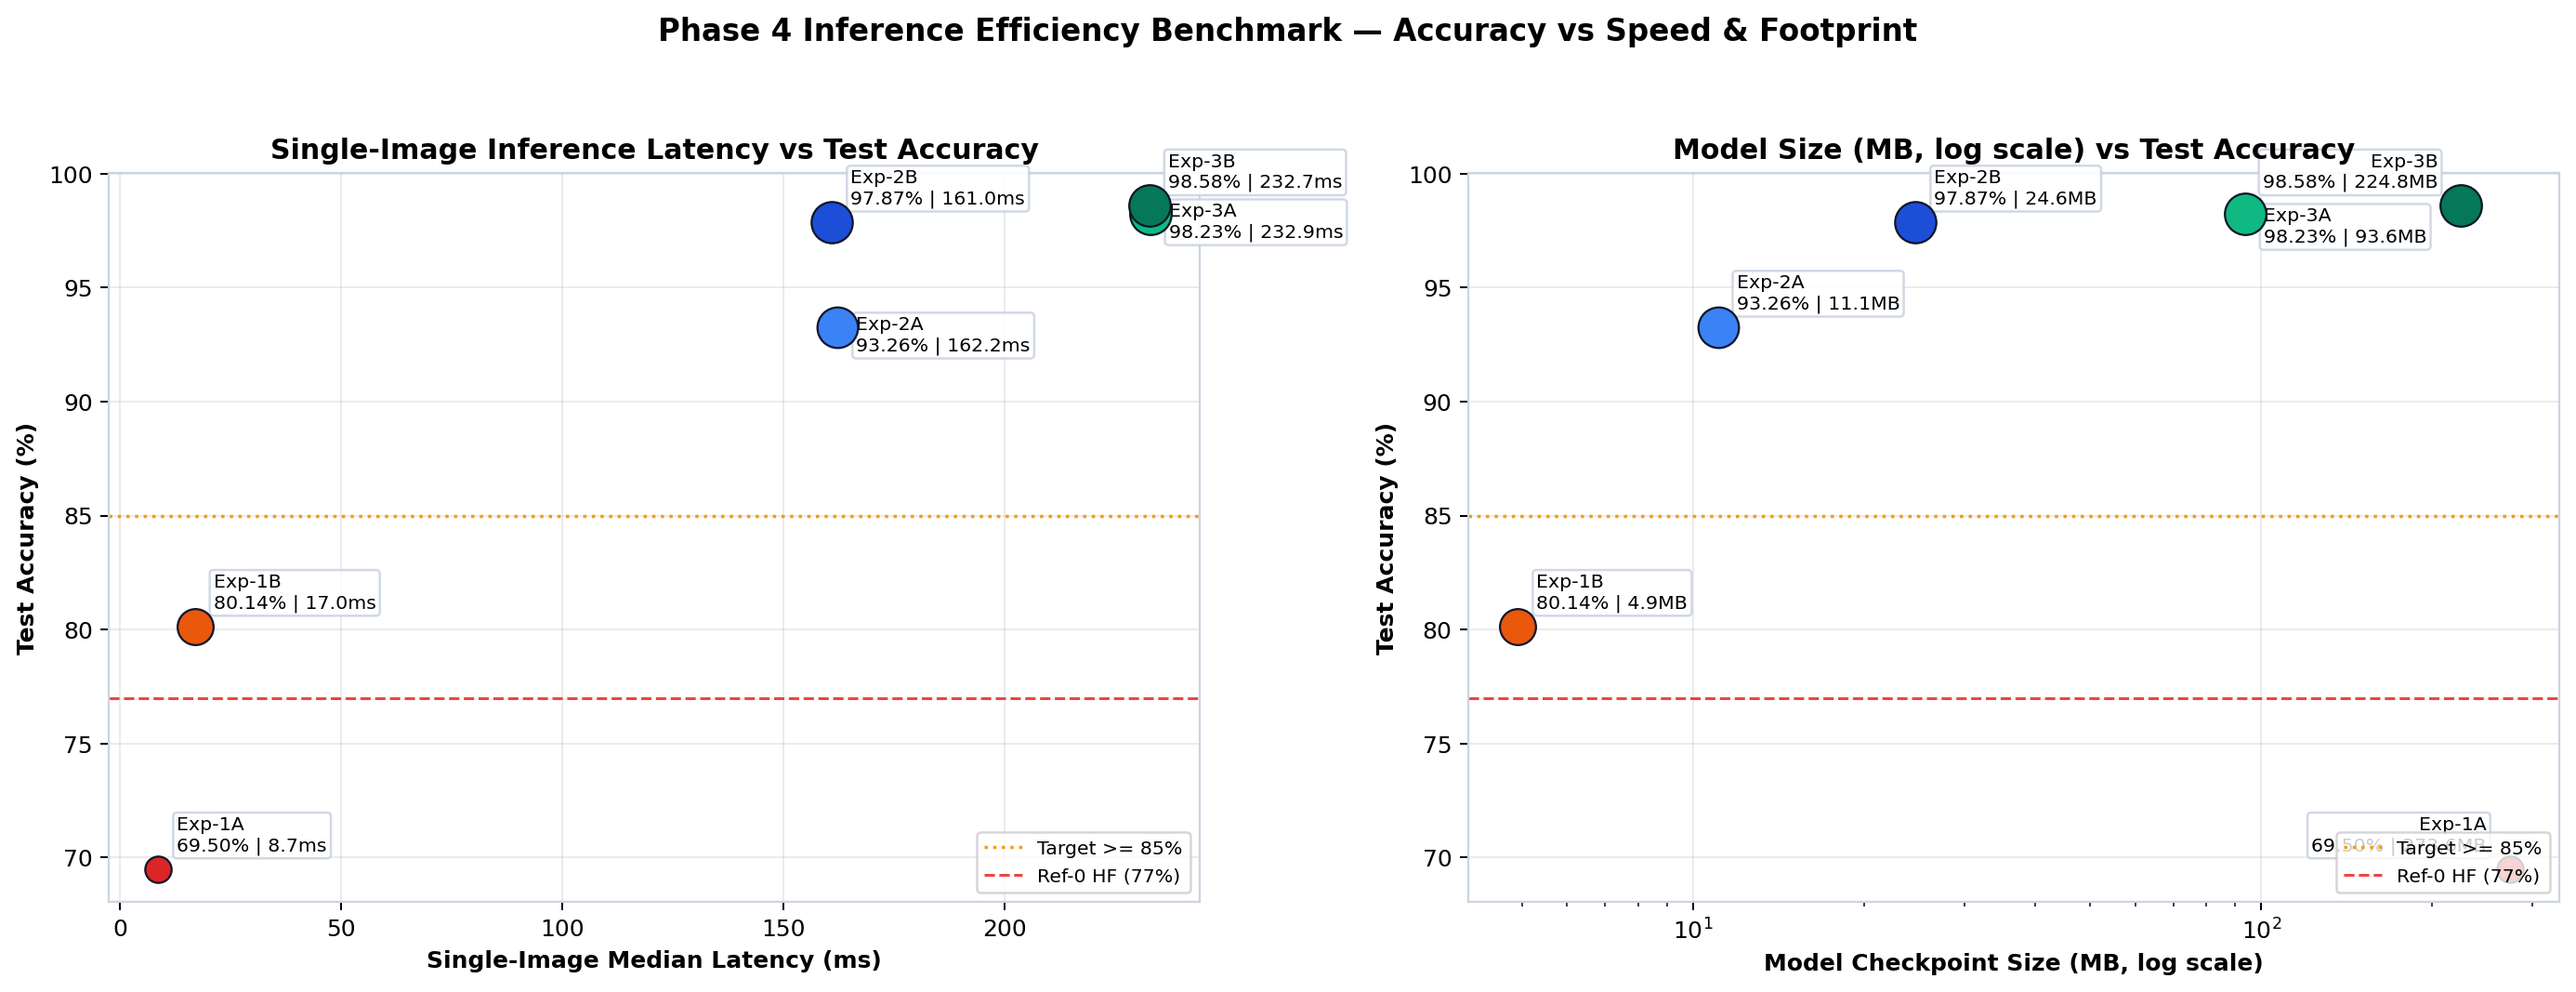

Saved: /content/real-art-vs-ai-generated-art/reports/figures/phase4_efficiency_benchmark.png


In [7]:
# Cell 5 — GPU Inference Efficiency & Pareto Benchmark (p4_latency)
x1 = tf.random.uniform((1, *IMG_SIZE, 3), minval=0.0, maxval=255.0, dtype=tf.float32)
x32 = tf.random.uniform((32, *IMG_SIZE, 3), minval=0.0, maxval=255.0, dtype=tf.float32)

latency_metrics = {}
lat_rows = []
for spec in MODEL_SPECS:
    rid = spec['run_id']
    model = MODELS[rid]

    # Warmup
    for _ in range(10):
        _ = model(x1, training=False).numpy()
    for _ in range(5):
        _ = model(x32, training=False).numpy()

    # Single-image latency (100 runs)
    s_times_ms = []
    for _ in range(100):
        t0 = time.perf_counter()
        _ = model(x1, training=False).numpy()
        s_times_ms.append((time.perf_counter() - t0) * 1000.0)

    # Batch-32 throughput (20 runs)
    b_times_ms = []
    for _ in range(20):
        t0 = time.perf_counter()
        _ = model(x32, training=False).numpy()
        b_times_ms.append((time.perf_counter() - t0) * 1000.0)

    single_mean = round(float(np.mean(s_times_ms)), 2)
    single_med = round(float(np.median(s_times_ms)), 2)
    single_p95 = round(float(np.percentile(s_times_ms, 95)), 2)
    batch_per_img = round(float(np.median(b_times_ms) / 32.0), 2)
    throughput = round(float(1000.0 / batch_per_img), 1)

    latency_metrics[rid] = {
        'single_ms_mean': single_mean,
        'single_ms_median': single_med,
        'single_ms_p95': single_p95,
        'batch32_ms_per_img': batch_per_img,
        'throughput_img_per_sec': throughput,
    }
    lat_rows.append({
        'Run ID': rid,
        'Model': spec['short_name'],
        'Params': f"{MODEL_META[rid]['params_total']:,}",
        'Size (MB)': MODEL_META[rid]['model_size_mb'],
        'Test Acc': f"{test_default_metrics[rid]['accuracy']*100:.2f}%",
        'Single Median (ms)': single_med,
        'Single P95 (ms)': single_p95,
        'Batch32 ms/img': batch_per_img,
        'Throughput (img/s)': throughput,
    })

display(pd.DataFrame(lat_rows))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 6.0), dpi=180)
fig.patch.set_facecolor('white')

for spec in MODEL_SPECS:
    rid = spec['run_id']
    t_acc = test_default_metrics[rid]['accuracy'] * 100.0
    lat = latency_metrics[rid]['single_ms_median']
    sz = MODEL_META[rid]['model_size_mb']
    auc = test_default_metrics[rid]['roc_auc']
    marker_sz = 120 + (auc - 0.80) * 1000

    ax1.scatter([lat], [t_acc], s=marker_sz, color=spec['color'], edgecolors='#0f172a', linewidths=0.9, zorder=4)
    ax1.annotate(
        f"{rid}\n{t_acc:.2f}% | {lat:.1f}ms",
        xy=(lat, t_acc),
        xytext=(8, -10 if rid in ('Exp-2A', 'Exp-3A') else 8),
        textcoords='offset points',
        fontsize=8.2,
        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='#cbd5e1', alpha=0.9),
    )

    ax2.scatter([sz], [t_acc], s=marker_sz, color=spec['color'], edgecolors='#0f172a', linewidths=0.9, zorder=4)
    ax2.annotate(
        f"{rid}\n{t_acc:.2f}% | {sz:.1f}MB",
        xy=(sz, t_acc),
        xytext=(-10 if sz > 150 else 8, -12 if rid == 'Exp-3A' else 8),
        textcoords='offset points',
        ha='right' if sz > 150 else 'left',
        fontsize=8.2,
        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='#cbd5e1', alpha=0.9),
    )

for ax in (ax1, ax2):
    ax.axhline(85.0, color='#f59e0b', linestyle=':', linewidth=1.4, label='Target >= 85%')
    ax.axhline(77.0, color='#ef4444', linestyle='--', linewidth=1.2, label='Ref-0 HF (77%)')
    ax.grid(alpha=0.25)
    ax.set_ylabel('Test Accuracy (%)', fontweight='bold')
    ax.legend(fontsize=8.2, loc='lower right')

ax1.set_title('Single-Image Inference Latency vs Test Accuracy', fontweight='bold')
ax1.set_xlabel('Single-Image Median Latency (ms)', fontweight='bold')

ax2.set_xscale('log')
ax2.set_title('Model Size (MB, log scale) vs Test Accuracy', fontweight='bold')
ax2.set_xlabel('Model Checkpoint Size (MB, log scale)', fontweight='bold')

fig.suptitle('Phase 4 Inference Efficiency Benchmark — Accuracy vs Speed & Footprint', fontsize=13, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.94])
eff_path = FIGURES_DIR / 'phase4_efficiency_benchmark.png'
fig.savefig(eff_path, dpi=180, bbox_inches='tight')
plt.show()
print('Saved:', eff_path)

In [8]:
# Cell 6 — Visual Error Analysis on Test Set (p4_err)
def center_crop_pil(path: Path, size: tuple[int, int] = IMG_SIZE) -> Image.Image:
    with Image.open(path) as im:
        im = im.convert('RGB')
        w, h = im.size
        side = min(w, h)
        left = (w - side) // 2
        top = (h - side) // 2
        return im.crop((left, top, left + side, top + side)).resize(size, Image.Resampling.BILINEAR)

meta_df = pd.read_csv(PROCESSED_DIR / 'dataset_metadata.csv')[
    ['sample_id', 'width', 'height', 'aspect_ratio', 'orig_format', 'byte_size']
]
err_df = test_pred_df.merge(meta_df, on='sample_id', how='left')

err_df['pred_2b'] = (err_df['prob_Exp-2B'] >= 0.50).astype(int)
err_df['pred_3b'] = (err_df['prob_Exp-3B'] >= 0.50).astype(int)
err_df['err_2b'] = err_df['pred_2b'] != err_df['true_label']
err_df['err_3b'] = err_df['pred_3b'] != err_df['true_label']
err_df['any_err'] = err_df['err_2b'] | err_df['err_3b']
err_df['disagree'] = err_df['pred_2b'] != err_df['pred_3b']
err_df['is_square'] = (err_df['aspect_ratio'] >= 0.95) & (err_df['aspect_ratio'] <= 1.05)
err_df['margin'] = np.minimum(np.abs(err_df['prob_Exp-2B'] - 0.50), np.abs(err_df['prob_Exp-3B'] - 0.50))

def tag_row(r):
    if r['err_2b'] and r['err_3b']:
        return 'BOTH FP' if r['true_label'] == 0 else 'BOTH FN'
    if r['err_2b']:
        return '2B FP' if r['true_label'] == 0 else '2B FN'
    if r['err_3b']:
        return '3B FP' if r['true_label'] == 0 else '3B FN'
    return 'BORDERLINE'

err_df['badge'] = err_df.apply(tag_row, axis=1)

# Metadata comparison: Error/Disagree vs Correct Both
stats_rows = []
for grp_name, mask in [
    ('Error (2B or 3B)', err_df['any_err']),
    ('Correct Both (2B & 3B)', ~err_df['any_err']),
]:
    sub = err_df[mask]
    if len(sub) > 0:
        stats_rows.append({
            'Group': grp_name,
            'Count': int(len(sub)),
            'Real / AI': f"{int((sub['true_label']==0).sum())} / {int((sub['true_label']==1).sum())}",
            'Mean Aspect Ratio': round(float(sub['aspect_ratio'].mean()), 3),
            '% Square (0.95-1.05)': round(float(sub['is_square'].mean() * 100), 1),
            '% PNG Format': round(float((sub['orig_format'] == 'PNG').mean() * 100), 1),
            'Median W×H': f"{int(sub['width'].median())}×{int(sub['height'].median())}",
        })
error_stats_df = pd.DataFrame(stats_rows)
display(error_stats_df)

# Select errors + disagreements, pad to at least 12 (max 16) with borderline correct samples
focus_df = err_df[err_df['any_err'] | err_df['disagree']].sort_values('margin').copy()
if len(focus_df) < 12:
    pad_n = 12 - len(focus_df)
    pad_df = err_df[~err_df.index.isin(focus_df.index)].sort_values('margin').head(pad_n)
    focus_df = pd.concat([focus_df, pad_df], ignore_index=True)
focus_df = focus_df.head(16).reset_index(drop=True)

ncols = 4
nrows = math.ceil(len(focus_df) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(15.5, 4.1 * nrows), dpi=180)
fig.patch.set_facecolor('white')
axes_flat = np.atleast_1d(axes).ravel()

for ax, (_, row) in zip(axes_flat, focus_df.iterrows()):
    img_path = PROCESSED_DIR / 'images' / row['filename']
    ax.imshow(center_crop_pil(img_path))
    badge_color = '#dc2626' if 'BOTH' in row['badge'] else ('#d97706' if row['badge'] != 'BORDERLINE' else '#2563eb')
    ax.set_title(
        f"[{row['badge']}] True: {row['true_name']}\n"
        f"2B P(AI)={row['prob_Exp-2B']:.3f} | 3B P(AI)={row['prob_Exp-3B']:.3f}\n"
        f"{row['width']}×{row['height']} {row['orig_format']}",
        fontsize=8.5,
        fontweight='bold',
        color=badge_color,
        pad=5,
    )
    ax.axis('off')
for ax in axes_flat[len(focus_df):]:
    ax.axis('off')

fig.suptitle(
    f"Phase 4 Test Set Error Analysis — Errors & Borderline Cases (Exp-2B: {int(err_df['err_2b'].sum())} err, Exp-3B: {int(err_df['err_3b'].sum())} err)",
    fontsize=12.5,
    fontweight='bold',
)
fig.tight_layout(rect=[0, 0, 1, 0.96])
err_grid_path = FIGURES_DIR / 'phase4_error_analysis_grid.png'
fig.savefig(err_grid_path, dpi=180, bbox_inches='tight')
plt.show()
print('Saved:', err_grid_path)

Output hidden; open in https://colab.research.google.com to view.

In [9]:
# Cell 7 — Keras 3 Pre-Sigmoid Logit Grad-CAM Comparison (RQ3, p4_gradcam)
def compute_gradcam_heatmap(
    model: keras.Model,
    img_rgb_224: np.ndarray,
    spatial_layer_name: str,
    target_class: int = 1,
) -> np.ndarray:
    """Compute Grad-CAM using pre-sigmoid logits to prevent sigmoid saturation."""
    layer_names = [lyr.name for lyr in model.layers]
    sp_idx = layer_names.index(spatial_layer_name)
    prob_idx = layer_names.index('prob_ai')

    pre_layers = model.layers[1 : sp_idx + 1]
    post_layers = model.layers[sp_idx + 1 : prob_idx]
    prob_layer = model.layers[prob_idx]

    img_batch = tf.convert_to_tensor(img_rgb_224[None, ...], dtype=tf.float32)
    with tf.GradientTape() as tape:
        x = img_batch
        for lyr in pre_layers:
            x = lyr(x, training=False)
        conv_out = x
        tape.watch(conv_out)
        for lyr in post_layers:
            x = lyr(x, training=False)
        logit = tf.matmul(x, prob_layer.kernel) + prob_layer.bias
        score = logit[:, 0] if target_class == 1 else -logit[:, 0]

    grads = tape.gradient(score, conv_out)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam = tf.reduce_sum(conv_out[0] * weights, axis=-1)
    cam = tf.nn.relu(cam)
    cam_max = tf.reduce_max(cam)
    if float(cam_max) > 1e-8:
        cam = cam / cam_max
    cam_resized = tf.image.resize(cam[..., None], IMG_SIZE, method='bilinear')[..., 0]
    return np.clip(cam_resized.numpy(), 0.0, 1.0)


def overlay_gradcam(img_uint8: np.ndarray, heatmap: np.ndarray, alpha: float = 0.42) -> np.ndarray:
    cmap = plt.get_cmap('jet')
    heat_rgb = (cmap(heatmap)[..., :3] * 255.0).astype(np.float32)
    blended = (1.0 - alpha) * img_uint8.astype(np.float32) + alpha * heat_rgb
    return np.clip(blended, 0, 255).astype(np.uint8)


# Pick 8 informative Test samples: 2 TP (AI), 2 TN (Real), 2 FP (or hardest Real), 2 FN (or hardest AI)
tp_pool = err_df[(err_df['true_label'] == 1) & (~err_df['err_3b'])].sort_values('prob_Exp-3B', ascending=False)
tn_pool = err_df[(err_df['true_label'] == 0) & (~err_df['err_3b'])].sort_values('prob_Exp-3B', ascending=True)
fp_pool = err_df[err_df['true_label'] == 0].sort_values('prob_Exp-3B', ascending=False)
fn_pool = err_df[err_df['true_label'] == 1].sort_values('prob_Exp-3B', ascending=True)

gradcam_picks = []
for group_tag, pool in [('TP (AI)', tp_pool), ('TN (Real)', tn_pool), ('FP / Hard Real', fp_pool), ('FN / Hard AI', fn_pool)]:
    for _, row in pool.head(2).iterrows():
        gradcam_picks.append((group_tag, row))

cam_models = [
    ('Exp-1B', 'Scratch CNN (relu_b4)', 'relu_b4'),
    ('Exp-2B', 'MobileNetV2 FT', 'mobilenetv2_1.00_224'),
    ('Exp-3B', 'ResNet50 FT', 'resnet50'),
]

fig, axes = plt.subplots(len(gradcam_picks), 4, figsize=(14.5, 3.3 * len(gradcam_picks)), dpi=170)
fig.patch.set_facecolor('white')

for r_idx, (group_tag, row) in enumerate(gradcam_picks):
    img_path = PROCESSED_DIR / 'images' / row['filename']
    pil_224 = center_crop_pil(img_path)
    img_u8 = np.array(pil_224, dtype=np.uint8)
    img_f32 = img_u8.astype(np.float32)

    ax0 = axes[r_idx, 0]
    ax0.imshow(img_u8)
    ax0.set_title(f"{group_tag}\nTrue: {row['true_name']}", fontsize=8.8, fontweight='bold')
    ax0.axis('off')

    for c_idx, (rid, mlabel, sp_name) in enumerate(cam_models, start=1):
        prob = float(row[f'prob_{rid}'])
        pred_cls = 1 if prob >= 0.50 else 0
        hmap = compute_gradcam_heatmap(MODELS[rid], img_f32, sp_name, target_class=pred_cls)
        ax = axes[r_idx, c_idx]
        ax.imshow(overlay_gradcam(img_u8, hmap))
        ok = pred_cls == int(row['true_label'])
        ax.set_title(
            f"{rid} {mlabel}\nPred: {LABEL_MAP[pred_cls]} (P(AI)={prob:.3f})",
            fontsize=8.4,
            fontweight='bold',
            color='#15803d' if ok else '#dc2626',
        )
        ax.axis('off')

fig.suptitle('Phase 4 Grad-CAM (Pre-Sigmoid Logits) — Scratch CNN vs MobileNetV2 FT vs ResNet50 FT', fontsize=13, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.975])
gradcam_path = FIGURES_DIR / 'phase4_gradcam_comparison.png'
fig.savefig(gradcam_path, dpi=170, bbox_inches='tight')
plt.show()
print('Saved:', gradcam_path)

Output hidden; open in https://colab.research.google.com to view.

In [10]:
# Cell 8 — Out-of-Distribution (OOD) Stress Test on 30 External Images (RQ4, p4_ood)
ood_df = pd.read_csv(OOD_DIR / 'ood_metadata.csv')
ood_paths = [str(OOD_DIR / 'images' / fn) for fn in ood_df['filename']]
ood_labels = ood_df['label'].to_numpy(dtype=int)

ood_ds = tf.data.Dataset.from_tensor_slices((ood_paths, ood_labels.astype('float32')))
ood_ds = ood_ds.map(
    lambda fp, lbl: _decode_and_resize(fp, lbl, IMG_SIZE, center_crop=True),
    num_parallel_calls=tf.data.AUTOTUNE,
).batch(32).prefetch(tf.data.AUTOTUNE)

ood_probs = {}
ood_default_metrics = {}
ood_tuned_metrics = {}
ood_source_acc = {}

ood_pred_df = ood_df.copy()
ood_summary_rows = []
source_groups = ['WikiArt_Museum', 'Midjourney_v6', 'FLUX_1_Dev', 'DALLE_3']

for spec in MODEL_SPECS:
    rid = spec['run_id']
    probs = MODELS[rid].predict(ood_ds, verbose=0).ravel()
    ood_probs[rid] = probs
    ood_pred_df[f'prob_{rid}'] = np.round(probs, 6)
    ood_pred_df[f'pred_{rid}'] = (probs >= 0.50).astype(int)

    om = compute_binary_metrics(ood_labels, probs, threshold=0.50)
    ot = compute_binary_metrics(ood_labels, probs, threshold=optimal_thresholds[rid])
    ood_default_metrics[rid] = om
    ood_tuned_metrics[rid] = ot

    src_map = {}
    for sg in source_groups:
        mask = ood_df['source_group'].to_numpy() == sg
        src_map[sg] = round(float(accuracy_score(ood_labels[mask], (probs[mask] >= 0.50).astype(int))), 4)
    ood_source_acc[rid] = src_map

    drop_pp = round((om['accuracy'] - test_default_metrics[rid]['accuracy']) * 100, 2)
    ood_summary_rows.append({
        'Run ID': rid,
        'Model': spec['short_name'],
        'Test Acc': f"{test_default_metrics[rid]['accuracy']*100:.2f}%",
        'OOD Acc @0.50': f"{om['accuracy']*100:.2f}%",
        'Drop (pp)': drop_pp,
        'OOD F1': om['f1'],
        'OOD ROC-AUC': om['roc_auc'],
        'OOD Acc @t*': f"{ot['accuracy']*100:.2f}%",
        'WikiArt (15)': f"{src_map['WikiArt_Museum']*100:.1f}%",
        'MJ v6 (5)': f"{src_map['Midjourney_v6']*100:.1f}%",
        'FLUX.1 (5)': f"{src_map['FLUX_1_Dev']*100:.1f}%",
        'DALL-E 3 (5)': f"{src_map['DALLE_3']*100:.1f}%",
    })

ood_pred_csv = EXPERIMENTS_DIR / 'phase4_ood_predictions.csv'
ood_pred_df.to_csv(ood_pred_csv, index=False)
display(pd.DataFrame(ood_summary_rows))

# Plot 1: Test vs OOD Bar + Per-Source Accuracy Heatmap
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.8, 6.0), dpi=180, gridspec_kw={'width_ratios': [1.05, 1.0]})
fig.patch.set_facecolor('white')

x = np.arange(len(MODEL_SPECS))
w = 0.36
test_accs = [test_default_metrics[s['run_id']]['accuracy'] * 100 for s in MODEL_SPECS]
ood_accs = [ood_default_metrics[s['run_id']]['accuracy'] * 100 for s in MODEL_SPECS]

b1 = ax1.bar(x - w/2, test_accs, width=w, color='#2563eb', label='In-Dist Test Acc (N=282)')
b2 = ax1.bar(x + w/2, ood_accs, width=w, color='#f97316', label='OOD Stress Test Acc (N=30)')
for rect, val in zip(b1, test_accs):
    ax1.text(rect.get_x() + rect.get_width()/2, val + 1.0, f'{val:.1f}%', ha='center', va='bottom', fontsize=8.0, fontweight='bold', color='#1e3a8a')
for rect, val, ta in zip(b2, ood_accs, test_accs):
    ax1.text(rect.get_x() + rect.get_width()/2, val + 1.0, f'{val:.1f}%\n({val-ta:+.1f})', ha='center', va='bottom', fontsize=7.6, fontweight='bold', color='#9a3412')

ax1.axhline(50.0, color='#94a3b8', linestyle='--', linewidth=1.2, label='Random Guess (50%)')
ax1.set_xticks(x)
ax1.set_xticklabels([f"{s['run_id']}\n{s['short_name']}" for s in MODEL_SPECS], fontsize=8.4)
ax1.set_ylim(0, 114)
ax1.set_ylabel('Accuracy (%)', fontweight='bold')
ax1.set_title('Generalization Gap: In-Distribution Test vs OOD Stress Test', fontweight='bold')
ax1.grid(axis='y', alpha=0.25)
ax1.legend(fontsize=8.2, loc='lower left')

heat_mat = np.array([[ood_source_acc[s['run_id']][sg] * 100 for sg in source_groups] for s in MODEL_SPECS])
sns.heatmap(
    heat_mat,
    annot=True,
    fmt='.1f',
    cmap='RdYlGn',
    vmin=0,
    vmax=100,
    ax=ax2,
    xticklabels=['WikiArt\n(15 Real)', 'Midjourney v6\n(5 AI)', 'FLUX.1-Dev\n(5 AI)', 'DALL-E 3\n(5 AI)'],
    yticklabels=[f"{s['run_id']} ({s['short_name']})" for s in MODEL_SPECS],
    cbar_kws={'label': 'Accuracy (%)'},
    annot_kws={'fontsize': 9.5, 'fontweight': 'bold'},
)
ax2.set_title('OOD Accuracy (%) Breakdown per External Source', fontweight='bold')

fig.suptitle('Phase 4 OOD Stress Test (N = 30 External Images, Min pHash Distance >= 14)', fontsize=13, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.94])
ood_break_path = FIGURES_DIR / 'phase4_ood_breakdown.png'
fig.savefig(ood_break_path, dpi=180, bbox_inches='tight')
plt.show()

# Plot 2: 6 OOD Grad-CAM Showcase Samples (2 WikiArt, 2 Modern AI caught, 2 hardest/fooled OOD)
ood_pred_df['err_3b'] = ood_pred_df['pred_Exp-3B'] != ood_pred_df['label']
ood_pred_df['err_2b'] = ood_pred_df['pred_Exp-2B'] != ood_pred_df['label']
ood_pred_df['correct_score'] = np.where(
    ood_pred_df['label'] == 1,
    ood_pred_df['prob_Exp-3B'],
    1.0 - ood_pred_df['prob_Exp-3B'],
)

wiki_best = ood_pred_df[ood_pred_df['source_group'] == 'WikiArt_Museum'].sort_values('correct_score', ascending=False).head(2)
ai_best = ood_pred_df[ood_pred_df['label'] == 1].sort_values('correct_score', ascending=False).head(2)
used_ids = set(wiki_best['ood_id']).union(set(ai_best['ood_id']))
hard_pool = ood_pred_df[~ood_pred_df['ood_id'].isin(used_ids)].sort_values('correct_score', ascending=True).head(2)
ood_showcase = pd.concat([wiki_best, ai_best, hard_pool], ignore_index=True)

fig, axes = plt.subplots(len(ood_showcase), 3, figsize=(11.5, 3.3 * len(ood_showcase)), dpi=170)
fig.patch.set_facecolor('white')
for r_idx, (_, row) in enumerate(ood_showcase.iterrows()):
    pil_224 = center_crop_pil(OOD_DIR / 'images' / row['filename'])
    img_u8 = np.array(pil_224, dtype=np.uint8)
    img_f32 = img_u8.astype(np.float32)

    ax0 = axes[r_idx, 0]
    ax0.imshow(img_u8)
    ax0.set_title(f"{row['ood_id']} ({row['source_group']})\nTrue: {row['label_name']}", fontsize=8.6, fontweight='bold')
    ax0.axis('off')

    for c_idx, (rid, mlabel, sp_name) in enumerate([
        ('Exp-2B', 'MobileNetV2 FT', 'mobilenetv2_1.00_224'),
        ('Exp-3B', 'ResNet50 FT', 'resnet50'),
    ], start=1):
        prob = float(row[f'prob_{rid}'])
        pred_cls = 1 if prob >= 0.50 else 0
        hmap = compute_gradcam_heatmap(MODELS[rid], img_f32, sp_name, target_class=pred_cls)
        ax = axes[r_idx, c_idx]
        ax.imshow(overlay_gradcam(img_u8, hmap))
        ok = pred_cls == int(row['label'])
        ax.set_title(
            f"{rid} {mlabel}\nPred: {LABEL_MAP[pred_cls]} (P(AI)={prob:.3f})",
            fontsize=8.4,
            fontweight='bold',
            color='#15803d' if ok else '#dc2626',
        )
        ax.axis('off')

fig.suptitle('Phase 4 OOD Grad-CAM Samples — WikiArt Museum & Modern AI Generators', fontsize=12.5, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.965])
ood_cam_path = FIGURES_DIR / 'phase4_ood_gradcam_samples.png'
fig.savefig(ood_cam_path, dpi=170, bbox_inches='tight')
plt.show()
print('Saved:', ood_break_path, 'and', ood_cam_path)

Output hidden; open in https://colab.research.google.com to view.

In [11]:
# Cell 9 — Save Master phase4_summary.json & Auto-Sync All Outputs to Google Drive
phase4_summary = {
    'timestamp': datetime.now().astimezone().isoformat(),
    'environment': {
        'in_colab': IN_COLAB,
        'tensorflow': tf.__version__,
        'keras': keras.__version__,
        'gpus': [g.name for g in gpus],
    },
    'threshold_tuning_val': {
        'optimal_thresholds': optimal_thresholds,
        'val_default_050': val_default_metrics,
        'val_tuned': val_tuned_metrics,
    },
    'test_set_evaluation': {
        'n_samples': int(len(y_test)),
        'test_default_050': test_default_metrics,
        'test_tuned': test_tuned_metrics,
        'mcnemar_exp2b_vs_exp3b': mcnemar_summary,
    },
    'inference_efficiency': {
        rid: {
            'params_total': MODEL_META[rid]['params_total'],
            'params_trainable': MODEL_META[rid]['params_trainable'],
            'model_size_mb': MODEL_META[rid]['model_size_mb'],
            **latency_metrics[rid],
        }
        for rid in [s['run_id'] for s in MODEL_SPECS]
    },
    'error_analysis_summary': error_stats_df.to_dict(orient='records'),
    'ood_stress_test': {
        'n_samples': int(len(ood_labels)),
        'ood_default_050': ood_default_metrics,
        'ood_tuned': ood_tuned_metrics,
        'ood_per_source_acc_050': ood_source_acc,
    },
}

summary_path = EXPERIMENTS_DIR / 'phase4_summary.json'
summary_path.write_text(json.dumps(phase4_summary, indent=2), encoding='utf-8')
print('Saved summary JSON:', summary_path)

PHASE4_FIGURES = [
    'phase4_threshold_tuning.png',
    'phase4_test_roc_pr_curves.png',
    'phase4_test_confusion_matrices.png',
    'phase4_efficiency_benchmark.png',
    'phase4_error_analysis_grid.png',
    'phase4_gradcam_comparison.png',
    'phase4_ood_breakdown.png',
    'phase4_ood_gradcam_samples.png',
]

if IN_COLAB:
    drive_root = Path('/content/drive/MyDrive/Real-vs-AI-Art-Classification')
    if drive_root.exists():
        out_dir = drive_root / '01_Docs_&_Logs' / 'phase4_outputs'
        fig_dir = drive_root / '03_Figures_&_Visuals'
        out_dir.mkdir(parents=True, exist_ok=True)
        fig_dir.mkdir(parents=True, exist_ok=True)

        for fpath in (
            summary_path,
            test_pred_csv,
            ood_pred_csv,
            EXPERIMENT_LOG_PATH,
        ):
            shutil.copy2(fpath, out_dir / fpath.name)

        for fig_name in PHASE4_FIGURES:
            shutil.copy2(FIGURES_DIR / fig_name, fig_dir / fig_name)

        print('Auto-saved Phase 4 JSON/CSVs and 8 PNG figures to Google Drive!')
    else:
        print('Warning: Google Drive folder not found at', drive_root)

print(json.dumps({
    'test_default_050': {k: {'acc': v['accuracy'], 'f1': v['f1'], 'roc_auc': v['roc_auc'], 'errors': v['errors']} for k, v in test_default_metrics.items()},
    'ood_default_050': {k: {'acc': v['accuracy'], 'f1': v['f1'], 'roc_auc': v['roc_auc'], 'errors': v['errors']} for k, v in ood_default_metrics.items()},
}, indent=2))

Saved summary JSON: /content/real-art-vs-ai-generated-art/experiments/phase4_summary.json
Auto-saved Phase 4 JSON/CSVs and 8 PNG figures to Google Drive!
{
  "test_default_050": {
    "Exp-1A": {
      "acc": 0.695,
      "f1": 0.6161,
      "roc_auc": 0.8085,
      "errors": 86
    },
    "Exp-1B": {
      "acc": 0.8014,
      "f1": 0.7705,
      "roc_auc": 0.9198,
      "errors": 56
    },
    "Exp-2A": {
      "acc": 0.9326,
      "f1": 0.9309,
      "roc_auc": 0.9845,
      "errors": 19
    },
    "Exp-2B": {
      "acc": 0.9787,
      "f1": 0.9786,
      "roc_auc": 0.9948,
      "errors": 6
    },
    "Exp-3A": {
      "acc": 0.9823,
      "f1": 0.9822,
      "roc_auc": 0.9981,
      "errors": 5
    },
    "Exp-3B": {
      "acc": 0.9858,
      "f1": 0.9858,
      "roc_auc": 0.9985,
      "errors": 4
    }
  },
  "ood_default_050": {
    "Exp-1A": {
      "acc": 0.7333,
      "f1": 0.7333,
      "roc_auc": 0.7333,
      "errors": 8
    },
    "Exp-1B": {
      "acc": 0.7333,
     